# Chapter 28: Spatial Data Cubes

*Part VI — Data, Reproducibility & Verification*

Implemented by the [DisSCube](https://github.com/DisSModel/disscube) package (`disscube` 0.6.0 on PyPI).

<div class="admonition note">
<p class="admonition-title">Two kinds of example</p>
<p>The cells that run in this chapter use a small synthetic raster, so they work offline in a few seconds. The real case, the state of Pará built from MapBiomas, PRODES and the Brazil Data Cube, needs network access and several minutes; it is shown from its recorded run in the <a href="https://github.com/LambdaGeo/disscube-grids">disscube-grids</a> repository, with the commands to repeat it.</p>
</div>

## Learning Objectives

By the end of this chapter you will be able to:

- Explain why a data cube is a guarantee of alignment and indexability, not a file format
- Tell the cube at rest (DisSCube) from the cube in motion (`RasterBackend`)
- Declare a grid, its sources and its derived variables in a pipeline file, and run it with the `disscube` command
- Read the record a run leaves behind: the checksum of every source, the `spec_hash` of every product, the `content_hash` of its data
- Hand derived variables to a running DisSModel model

In [1]:
# Standard imports — add chapter-specific imports below
import json
import numpy as np
import matplotlib.pyplot as plt

Chapters 26 and 27 ran domain models on input data that was already prepared. This chapter is about what feeds a model in the first place — the raw rasters, vectors, and satellite scenes a real model needs prepared, aligned, and ready before a single tick runs. Chapter 16 did this by hand for one grid over Amazonas, with `rasterstats`, `rasterio.features` and `shapely`. DisSCube does the same work from a declaration: you write *what* each cell should hold, and the package does the reading, aligning and aggregating, and keeps a record of it. TerraME and TerraLib called this operation *filling* a cellular space; DisSCube's full name, *Declarative spatial data cubes*, says what it turns that operation into.

## What Is a Data Cube

In the Earth-observation literature, a **data cube** is a regular multidimensional array — typically `(variable, time, y, x)` — with three properties an arbitrary folder of files doesn't have:

1. **Spatial alignment.** Every variable, every date, shares the same grid — same CRS, resolution, and origin. Cell `(i, j)` is the same physical location no matter which variable or which date you're looking at.
2. **An explicit, indexable time axis.** Time is a dimension you can query, not a filename suffix.
3. **Analysis-ready.** The cost of reprojecting and aligning data is paid once, at ingestion — not recomputed on every single query.

A common misconception is that a cube has to be one giant file. It doesn't — a cube can be **virtual** (nothing computed yet, the array a promise resolved only when queried) just as legitimately as **materialized** (pixels already computed and written to disk). What makes something a data cube is the *guarantee* — alignment plus indexability — not any particular storage format.

## Two Regimes: The Cube at Rest, the Cube in Motion

The DisSModel ecosystem doesn't build one cube implementation — it builds two, on purpose, because a cube gets used for genuinely different things depending on where it sits in a pipeline:

| | DisSCube (rest) | `RasterBackend` (motion) |
|---|---|---|
| Role | cube infrastructure | one cube instance |
| Persistence | yes — Zarr files and a catalog | no — lives in process memory |
| Scope | a *family* of cubes, multi-grid | one cube, one grid, one run |
| Typical consumer | analysis, export, a model's input file | a running `Environment` (Chapter 21) |

Both satisfy the three-property definition above. The difference that matters is **when the values exist**. A cellular automaton needs the *concrete* value at step `t` to decide the transition to `t+1`, so `RasterBackend` holds plain NumPy arrays in memory and is changed in place, tick after tick. DisSCube works before the run: it computes each variable once, writes it to disk, and returns it from the catalog every time it is asked for again. The boundary between the two regimes is a single call, `to_raster_backend()`, at the end of this chapter.

## DisSCube: From Sources to Variables

DisSCube turns raw sources into named, grid-aligned, cataloged variables through one pipeline:

```
SpatialSource  →  Derivation  →  DerivedVariable (Zarr, in the catalog)
                       │
                    GridSpec
```

- **`GridSpec`** is the alignment contract itself: an ID, a CRS, a resolution, a bounding box. Every variable derived on the same `GridSpec` is comparable cell by cell by construction; a variable derived on a *different* grid is a different cube, even if it covers the same physical area. Without an explicit CRS, DisSCube builds the grid in the Albers projection of the Brazil Data Cube (EPSG:10857) and *snaps* its corners to multiples of the cell size, so that any two grids of the same resolution line up with each other and with the national mesh.
- **`SpatialSource`** is a raw input registered in the catalog — a local file, a MapBiomas or PRODES map, a Brazil Data Cube collection, OpenStreetMap roads, a digital elevation model — with its CRS, its time, and the **SHA-256 checksum** of the file actually read.
- **`Derivation`** is a declarative recipe: which **operator**, applied to which source, produces which named target variable. A derivation does not name a grid, so the same recipe can run on a 1 km grid and on a 5 km grid and produce two separate products.
- **`DerivedVariable`** is what a recipe produces on one grid: a Zarr array on disk, registered with two hashes that answer different questions. The **`spec_hash`** identifies the *request* — the recipe, the grid, the time window and the checksum of the source — and is the cache key: ask for the same thing twice and the catalog returns the stored product instead of computing it again. The **`content_hash`** identifies the *data* that came out. Two runs that should give the same result can be compared by their `content_hash`, whatever their file names.

There are two ways to drive this pipeline: a **pipeline file**, a TOML document run from the command line, and the **Python API**. The file is the recommended entry point, and the one the real cases use.

## A First Pipeline File

The example needs two input rasters. The cell below writes them: a synthetic 30 m land-use map of a 12 km × 12 km coastal strip (water to the west, a town in the middle, forest to the east, pasture between), with MapBiomas-style class codes, and an elevation raster rising inland. Nothing here is DisSCube yet — just `rasterio`, as in Chapter 8.

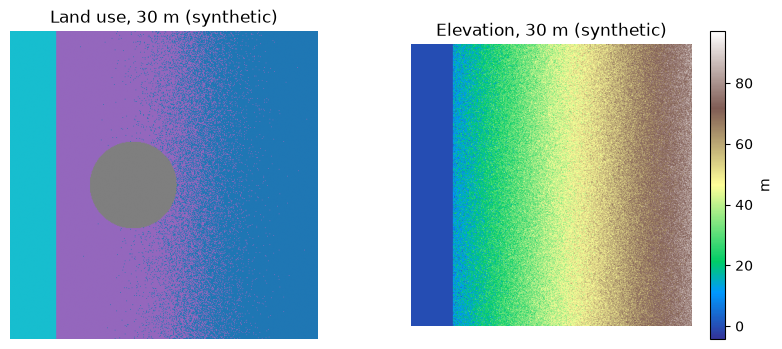

In [2]:
import shutil
from pathlib import Path
import rasterio
from rasterio.transform import from_origin

DEMO = Path("cube_demo")
shutil.rmtree(DEMO, ignore_errors=True)        # start from an empty folder every time
(DEMO / "raw").mkdir(parents=True)

CRS = "EPSG:31983"                              # SIRGAS 2000 / UTM zone 23S
ORIGIN = (570_000, 9_720_000)                   # upper-left corner, metres
FINE, N = 30.0, 400                             # 400 × 400 pixels of 30 m
FOREST, PASTURE, URBAN, WATER = 3, 15, 24, 33   # MapBiomas-style codes

rng = np.random.default_rng(42)
x = np.linspace(0, 1, N)[None, :].repeat(N, axis=0)
y = np.linspace(0, 1, N)[:, None].repeat(N, axis=1)

landuse = np.full((N, N), PASTURE, dtype="uint8")
landuse[x + 0.1 * rng.standard_normal((N, N)) > 0.6] = FOREST
landuse[(x - 0.4) ** 2 + (y - 0.5) ** 2 < 0.02] = URBAN
landuse[x < 0.15] = WATER

elevation = (80 * x + 5 * rng.standard_normal((N, N))).astype("float32")
elevation[landuse == WATER] = 0.0

for name, array in [("landuse", landuse), ("elevation", elevation)]:
    with rasterio.open(DEMO / "raw" / f"{name}.tif", "w", driver="GTiff", height=N, width=N, count=1,
                       dtype=array.dtype, crs=CRS, transform=from_origin(*ORIGIN, FINE, FINE)) as dst:
        dst.write(array, 1)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(landuse, cmap="tab10"); axes[0].set_title("Land use, 30 m (synthetic)")
im = axes[1].imshow(elevation, cmap="terrain"); axes[1].set_title("Elevation, 30 m (synthetic)")
fig.colorbar(im, ax=axes[1], label="m")
for ax in axes:
    ax.set_axis_off()
plt.show()

The pipeline file states everything about the preparation in one place: the grid (`[grid]`), each source (`[[source]]`) and each derived variable (`[[derive]]`). It is data, not code — there are no loops or conditions in it, and every line ends up in the record of the run:

In [3]:
pipeline = """
schema = 1
name = "Coast demo — land use and elevation on a 300 m grid"

[grid]
name = "coast/300m"
crs = "EPSG:31983"
bbox = [570000.0, 9708000.0, 582000.0, 9720000.0]
resolution = 300

[[source]]
id = "landuse"
type = "file"
path = "raw/landuse.tif"
crs = "EPSG:31983"

[[source]]
id = "elevation"
type = "file"
path = "raw/elevation.tif"
crs = "EPSG:31983"

[[derive]]
target = "forest_pct"           # share of the cell in class 3
source = "landuse"
operator = "percentage"
class_code = 3

[[derive]]
target = "landuse_major"        # the class that covers most of the cell
source = "landuse"
operator = "majority"

[[derive]]
target = "elev_mean"            # mean elevation of the cell
source = "elevation"
operator = "mean"
"""
_ = (DEMO / "coast.toml").write_text(pipeline)

`disscube validate` reads the file and plans the run without reading any data — a typo in an operator name or a source that does not exist fails here, before anything is downloaded:

In [4]:
!disscube validate cube_demo/coast.toml

pipeline  : coast.toml  (sha256:d0c05c5c1cf7…)
grid      : coast/300m  300 EPSG:31983
sources   : 2
  - landuse                  file
  - elevation                file
variables : 3
  - forest_pct               percentage(3) <- landuse
  - landuse_major            majority <- landuse
  - elev_mean                mean <- elevation
OK


`disscube run` does the work: it checksums each source, aligns it to the grid, applies each operator, stores the products in the workspace, and — with `--output` — exports them as one GeoTIFF with a band per variable:

In [5]:
!disscube run cube_demo/coast.toml --workspace cube_demo/work --output cube_demo/coast.tif

pipeline  : coast.toml  (sha256:d0c05c5c1cf7…)
grid      : coast/300m  300 EPSG:31983
sources   : 2
  - landuse                  file
  - elevation                file
variables : 3
  - forest_pct               percentage(3) <- landuse
  - landuse_major            majority <- landuse
  - elev_mean                mean <- elevation


workspace : cube_demo/work
derived   : 3 products on coast/300m
exported  : cube_demo/coast.tif
record    : cube_demo/work/run.json


`disscube plot` is a quick look at an exported GeoTIFF, one panel per band — a way to see whether the result is plausible, not a figure for a paper:

figure    : cube_demo/coast.png


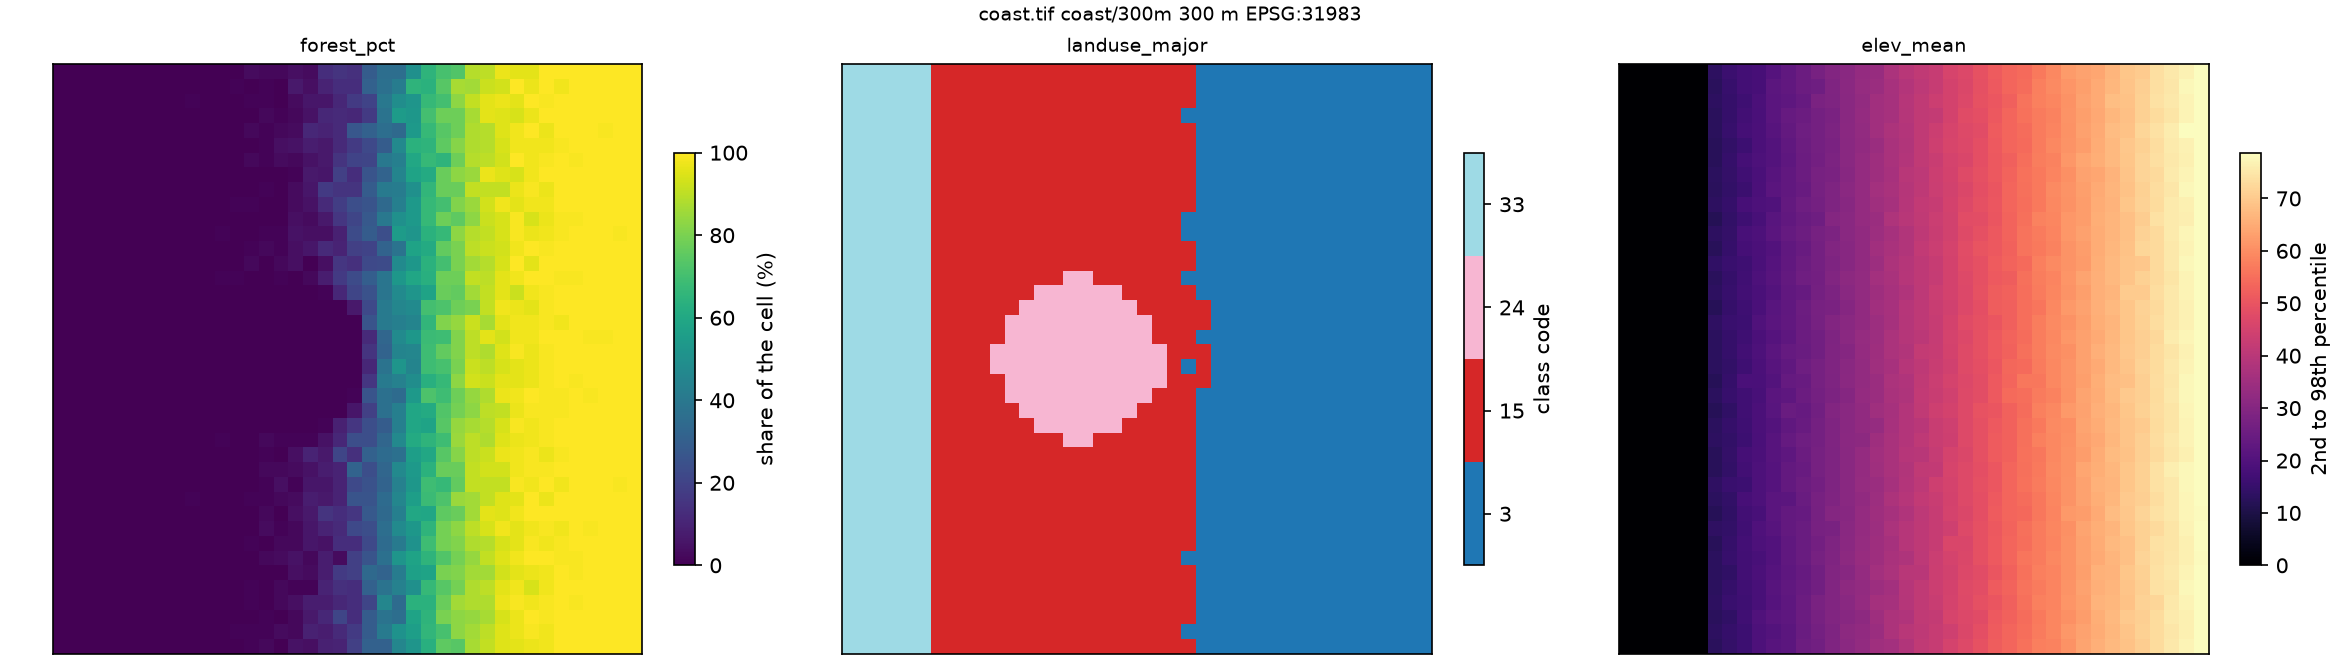

In [6]:
from IPython.display import Image

!disscube plot cube_demo/coast.tif -o cube_demo/coast.png --cols 3
Image("cube_demo/coast.png")

The 400 × 400 pixels of each source became a 40 × 40 grid of 300 m cells. The forest share rises to the east, the dominant class reproduces the four zones, and the mean elevation rises inland, as the inputs were built to do.

## What a Run Leaves Behind

The workspace now holds a catalog (`catalog.db`), the products (`store/`, Zarr) and `run.json`, the record of this run:

In [7]:
record = json.loads((DEMO / "work" / "run.json").read_text())
print("DisSCube :", record["disscube"])
print("pipeline :", record["pipeline"]["checksum"][:23], "…")
for s in record["sources"]:
    print(f"source   : {s['id']:10s} {s['checksum'][:23]}…")
for d in record["derived"]:
    print(f"product  : {d['target']:14s} spec_hash {d['spec_hash'][:12]}…")

DisSCube : 0.6.0
pipeline : sha256:d0c05c5c1cf7cf01 …
source   : landuse    sha256:ac6dd9de4826c135…
source   : elevation  sha256:560af8f4265d57f2…
product  : forest_pct     spec_hash aaa75f9e1e2f…
product  : landuse_major  spec_hash 3254a5be799f…
product  : elev_mean      spec_hash d0ed4854a6e3…


Every link of the chain is a hash: the pipeline file, each source file, each product. If someone edits the land-use raster and runs the pipeline again, its checksum changes, the `spec_hash` of every product that reads it changes with it, and DisSCube computes those products again instead of returning stale ones from the cache. Chapter 29 builds on exactly this record.

## The Operators

Each `[[derive]]` names one operator. Most of them are TerraME's `fill` operations under another name — the same four patterns Chapter 16 built by hand, and a few more:

| Operator | What each cell gets | TerraME `fill` |
|---|---|---|
| `mean`, `sum`, `min`, `max`, `std`, `median` | statistic of the source pixels in the cell | `average`, `sum`, `minimum`, `maximum`, `stdev` |
| `percentage` (with `class_code`) | share of the cell in one class (or a list of classes) | `coverage` |
| `majority`, `minority` | the most (least) common class | `majority`, `minority` |
| `presence`, `count` | whether a feature touches the cell; how many | `presence`, `count` |
| `attribute` | an attribute of the vector feature in the cell | — |
| `area` | exact share of the cell covered by polygons | `area` |
| `sum` with `params = {area = true}` | a polygon attribute shared in proportion to the area | `sum` with `area = true` |
| `distance` | exact distance from the cell centre to the nearest feature | `distance` |
| `min_distance` | raster approximation of the same distance | — |
| `network_cost` | cost of the cheapest route to a set of targets, along a road network | TerraME's network module (GPM) |

"The same operation under another name" is a claim that has to be measured, and the two do not always agree: Chapter 30 shows where DisSCube and TerraME's `fill` give the same value, where they differ for a documented reason, and the one case — `network_cost` — where the difference is not yet explained.

## A Real Case: the State of Pará

The same three blocks scale to real data. The pipeline file below is `cases/para/sources.toml` of the [disscube-grids](https://github.com/LambdaGeo/disscube-grids) repository, slightly shortened. It builds a 5 km grid over the whole state of Pará from two national products, each read at 30 m: the land use of MapBiomas Collection 11 and the deforestation map of PRODES (INPE), both for 2024.

```toml
schema = 1
name = "Pará — MapBiomas land use and PRODES deforestation"

[grid]
name = "para"
bbox = [-58.90, -9.85, -46.06, 2.64]        # WGS84 envelope of the state; the grid is BDC Albers, snapped
resolution = 5000

[[source]]
id = "lulc_{year}"
type = "mapbiomas"
years = [2024]
collection = 11
resolution = 30

[[source]]
id = "prodes_{year}"
type = "prodes"
years = [2024]

[source.codes]              # local code of each PRODES category
forest     = 1
deforested = 2              # deforested up to the year
non_forest = 3
water      = 4

[[derive]]
target = "l1_class"         # MapBiomas level 1: the class that covers most of the cell
source = "lulc_{year}"
operator = "majority"

[derive.params.groups]      # level-1 class = list of Collection 11 leaf codes
    "1" = [1, 3, 4, 5, 6, 49]                       # forest
    "2" = [10, 11, 12, 13, 29, 32, 50]              # herbaceous and shrubby vegetation
    "3" = [9, 14, 15, 18, 19, 20, 21, 35, 36, 39, 40, 41, 46, 47, 48, 62]   # farming
    "4" = [22, 23, 24, 25, 30, 75, 91]              # non-vegetated area
    "5" = [26, 31, 33]                              # water

[[derive]]
target = "prodes_class"
source = "prodes_{year}"
operator = "majority"
```

Four things in this file have no counterpart in the synthetic example:

- **No `crs` in `[grid]`.** The bounding box is in longitude and latitude, and DisSCube builds the grid in the Brazil Data Cube Albers projection, snapped to the national mesh: 280 × 291 cells of 5 km.
- **Sources by name, not by path.** `type = "mapbiomas"` and `type = "prodes"` tell DisSCube where the official files are; it downloads them (or reads them remotely), checksums them, and records the edition — for PRODES, `prodes_amazonia_legal_2025_v20260408`.
- **`years` and `{year}`.** A source with `years = [2024]` is expanded once per year; with `years = [2008, 2024]` the same file would produce a time series, which `load()` returns as a `(time, y, x)` array.
- **`groups`.** MapBiomas has dozens of leaf classes; `groups` gathers them into the five classes of its level 1 before the majority is taken, in the file, with no script. One choice in it is an assumption: code 91 appears in the 2024 map and is placed under non-vegetated area; it should be checked against the official legend before the map is used for anything but illustration.

To repeat the run (network access needed; MapBiomas is read remotely and PRODES, about 130 MB, is downloaded once into a cache):

```bash
git clone https://github.com/LambdaGeo/disscube-grids.git
cd disscube-grids && pip install -r requirements.txt
cd cases/para && ./run.sh run sources            # validate, then disscube run
./run.sh run bdc_ndvi                            # optional: Brazil Data Cube NDVI on the same grid
./run.sh run seats                               # optional: distance to the municipal seats on the same grid
./run.sh plot sources                            # the figure below
```

The recorded run of `sources.toml` (20 October 2026, DisSCube 0.6.0, on one desktop computer, Intel Core i7-7700T, 15 GB of RAM) took **2 min 12 s** with a peak memory of **1.2 GB**. The other two files of the folder add a third and a fourth source on the same grid: `bdc_ndvi.toml` reads the dry-season MODIS NDVI of 2020 from the Brazil Data Cube (7 min 15 s, 4.2 GB, mostly waiting for the network), and `seats.toml` declares the 5,570 municipal seats, a layer of points, and derives the distance from each cell to the nearest one (9 s, 0.21 GB).

![The state of Pará on a 5 km grid built by DisSCube from four sources](../../assets/images/para_sources.png)

*The state of Pará on a 5 km grid: (a) MapBiomas land use, 2024, the level-1 class that covers most of each cell; (b) PRODES, 2024, the class that covers most of the cell; (c) Brazil Data Cube MODIS NDVI, mean of the dry season of 2020; (d) distance to the nearest municipal seat, in km, with the seats as dots. Cells outside the state are masked with the IBGE boundary. Data: MapBiomas Project, Collection 11 (CC BY 4.0); INPE, PRODES (CC BY-SA 4.0); Didan (2021), MOD13Q1 V061, read through the Brazil Data Cube; IBGE, Bases Cartográficas Contínuas BC250 (2016), through the ANA metadata catalogue. Because it shows PRODES, this figure is under CC BY-SA 4.0, not under the CC BY 4.0 licence of the rest of the book. From [disscube-grids](https://github.com/LambdaGeo/disscube-grids), `docs/figures/para_sources.png`.*

The sources agree on the large pattern — the arc of deforestation in the east and south against the forest of the west and north — and differ where their definitions differ: PRODES marks less water than MapBiomas, so stretches of the large rivers appear as non-forest vegetation, and the herbaceous fields of Marajó are herbaceous vegetation in one and non-forest vegetation in the other. By cell, forest is the MapBiomas class that covers most of the cell in 75% of the cells of the state, farming in 19%, water in 3%. The figure is an example of ingestion, not a comparison of the products: they were made for different purposes and are not expected to agree cell by cell.

## Reading by Blocks

Each 30 m source over Pará is a window of about 2.2 billion pixels — far more than fits in memory at once on an ordinary computer. DisSCube reads the raster products of MapBiomas and PRODES **by blocks of rows and columns of the grid**: it reads one block of the source, aligns it to the matching block of cells, aggregates it, writes it, and moves on. The block size is set so that each block holds at most about 50 million source pixels (the environment variable `DISSCUBE_BLOCK_PIXELS` changes it). Each derived variable is one pass over its source; the Pará pipeline has two.

The same machinery covers much larger areas. Measured on the same desktop computer, each with a single pipeline file of the disscube-grids repository (the Pará row is the run of 20 October 2026 with the DisSCube 0.6.0 release; the other two are runs of 12 October with the code that became 0.6.0):

| Case | Source | Source pixels | Grid | Time | Peak memory |
|---|---|---|---|---|---|
| Pará | MapBiomas + PRODES, 2024 | ≈ 2.2 billion per source | 5 km, 280 × 291 | 2 min 12 s | 1.2 GB |
| Legal Amazon | PRODES, 2008 and 2024 | ≈ 9.7 billion | 5.28 km, 680 × 520 | 27 min 13 s | 2.9 GB |
| Brazil | MapBiomas, 2000, seven classes | 22.6 billion | 5.28 km, 900 × 1,040 | 1 h 43 min 55 s | 3.9 GB |

The memory grows with the size of a block, not with the size of the area. The time grows with both, because every derived variable is one more pass over the source. This is not the lazy, chunked computation of Dask from Chapter 9 — there is no task graph — but it answers the same question with a simpler mechanism: process a piece, keep the result, let the piece go. Sources other than MapBiomas and PRODES rasters (a local file, a Brazil Data Cube composite, a vector layer) are still read whole.

## The Python API: A Second Door

The pipeline file is turned into calls to the Python API, and the API can be used directly — to explore, to add one derivation to an existing cube, or to read products back. A `CubeClient` opened on the workspace of the run above sees everything the run stored:

In [8]:
from disscube import CubeClient, Derivation

cube = CubeClient(catalog="cube_demo/work/catalog.db", store="cube_demo/work/store")

forest = cube.load("forest_pct", grid_id="coast/300m")
print(type(forest).__name__, forest.dims, forest.shape)
print("mean forest share:", round(float(forest.mean()), 3))
print(cube.provenance("forest_pct", grid_id="coast/300m"))

DataArray ('y', 'x') (40, 40)
mean forest share: 0.397
[{'time': None, 'spec_hash': 'aaa75f9e1e2f495ac4410ff3b6d0bbb415169d32b0a1b7ed23fb2706be227f20', 'content_hash': 'e8a4076e6f455896270655d7070001dad8d7ec531ebf384e0f940285148ee564', 'source_id': 'landuse', 'source_checksum': 'sha256:ac6dd9de4826c135912edd78430c178484d9fa7568a8740318a41ab6cf58b9f5'}]


`load()` returns an `xarray.DataArray` (Chapter 9), and `provenance()` lists the hashes that identify the product: the `spec_hash` of the request, the `content_hash` of the stored data, and the checksum of the source it was computed from.

A new derivation on the same grid is one `Derivation` and one call. Asking for it a second time returns the stored product — the `spec_hash` is the same, so nothing is computed:

In [9]:
import time

water = Derivation(target="water_pct", source_id="landuse", operator="percentage", class_code=WATER)

t0 = time.perf_counter(); first = cube.derive_declarative(water, grid_id="coast/300m"); t1 = time.perf_counter()
again = cube.derive_declarative(water, grid_id="coast/300m"); t2 = time.perf_counter()

print(f"first call : {1000 * (t1 - t0):7.1f} ms   spec_hash {first[0].spec_hash[:12]}…")
print(f"second call: {1000 * (t2 - t1):7.1f} ms   spec_hash {again[0].spec_hash[:12]}…")

first call :   304.2 ms   spec_hash 032d1cece701…
second call:     1.7 ms   spec_hash 032d1cece701…


`to_dataset()` gathers several products into one `xarray.Dataset` with its CRS, and `export_geotiff()` / `export_netcdf()` write them out with their hashes in the metadata of each band:

In [10]:
ds = cube.to_dataset(["forest_pct", "water_pct", "landuse_major", "elev_mean"], grid_id="coast/300m")
print(list(ds.data_vars), dict(ds.sizes), ds.rio.crs)

['forest_pct', 'water_pct', 'landuse_major', 'elev_mean'] {'y': 40, 'x': 40} EPSG:31983


## Bridging to a Running Simulation

A `DataArray` is the cube at rest. A `RasterModel` (Chapters 22 and 24) needs the cube in motion — a `RasterBackend`. `to_raster_backend()` builds one from named products, with the grid's CRS and affine transform attached (it needs `pip install "disscube[dissmodel]"`, which only adds DisSModel itself):

In [11]:
backend = cube.to_raster_backend(["forest_pct", "elev_mean"], grid_id="coast/300m")
print(type(backend).__name__, backend.shape, backend.band_names())
print(backend.crs)

RasterBackend (40, 40) ['forest_pct', 'elev_mean']
EPSG:31983


From here on, nothing downstream knows the data came from DisSCube. A deliberately toy model — not a model of anything — shows the hand-off: every tick, cells below 60 m lose a tenth of their remaining forest share.

In [12]:
from dissmodel.core import Environment
from dissmodel.geo.raster.raster_model import RasterModel


class LowlandForestLoss(RasterModel):
    """Toy rule: cells below `threshold` metres lose `rate` of their forest share each tick."""

    def setup(self, backend, threshold=60.0, rate=0.1):
        super().setup(backend)
        self.threshold, self.rate = threshold, rate

    def execute(self):
        forest = self.backend.get("forest_pct").copy()
        low = self.backend.get("elev_mean") < self.threshold
        forest[low] *= 1 - self.rate
        self.backend.arrays["forest_pct"] = forest


before = float(np.nanmean(backend.get("forest_pct")))
env = Environment(start_time=0, end_time=4)
LowlandForestLoss(backend=backend)
env.run()
print(f"mean forest share: {before:.3f} before, {float(np.nanmean(backend.get('forest_pct'))):.3f} after 5 ticks")

Running from 0 to 4 (duration: 4)
mean forest share: 0.397 before, 0.335 after 5 ticks


`RasterBackend.from_xarray()` is the second door into the same substrate: any `xarray.Dataset` with `y` and `x` dimensions and named variables crosses into a simulation through it, whether DisSCube produced it or another tool did. Both doors lead to the same `RasterBackend`; a model never has to know which one was used.

In a reproducible workflow the hand-off is usually a file rather than a function call: the data stage exports a GeoTIFF, the model stage reads that GeoTIFF and records its SHA-256, and the model has no dependency on DisSCube at all. Chapter 31 is built that way.

## Multiple Cubes and Coupling

Three practical questions come up as soon as more than one grid enters a project:

- **Does a different grid mean a different cube?** Yes — the grid *is* a cube's identity. The same `Derivation` run on two different grids produces two separately cataloged results, each with its own `spec_hash`.
- **Does one model use only one cube?** One model *instance* does, since its transition rule assumes every driver variable is aligned to the same grid its own state lives on. An `Environment` (Chapter 21) can still coordinate several models at once, and nothing stops two different models from running on two different grids in the same `Environment`.
- **Do two grids in play always need runtime coupling?** Not if the crossing happens *before* the simulation starts — deriving a variable on a different grid ahead of time is just another `[[derive]]`, with the model itself never seeing more than one grid at once. Real runtime coupling — two models on different grids exchanging state every tick — is a harder, still-open problem in the ecosystem, one Chapter 35 returns to as an area of active work rather than a solved one.

## Exercises

1. **A second class.** Add a `[[derive]]` block to `coast.toml` for the share of urban land (`class_code = 24`), run the pipeline again, and look at `run.json`. Which products were computed again, and which came from the cache? How can you tell from the record?
2. **Change a source, watch the hashes.** Change one pixel of `raw/landuse.tif` (with `rasterio`), run the pipeline again, and compare the `spec_hash` of `forest_pct` and of `elev_mean` with the previous run. Which one changed, and why only that one?
3. **A finer grid.** Change `resolution` to 150 and the grid `name` to `coast/150m`. Do the `spec_hash` values of the 150 m and the 300 m products collide? Why must they differ?
4. **Read the Pará file.** Using the shortened `sources.toml` above, answer without running it: how many products does it create, and what would change if `years = [2024]` became `years = [2008, 2024]` in both sources?
5. **Rest or motion?** For each of the following, decide whether it belongs to DisSCube or to a `RasterBackend`, and justify it in one sentence: (a) the share of forest of each cell in 2008 and 2024; (b) a fire model reading a wind raster every tick; (c) the distance from each cell to the nearest road, before a run; (d) two coastal models exchanging flooded area every tick on different grids.

In [13]:
# Your code here

## Summary

### Key concepts introduced

- A data cube as a guarantee — spatial alignment, an indexable time axis, analysis-ready — not a file format
- Two regimes: DisSCube at rest (computed once, stored, cataloged, many grids) and `RasterBackend` in motion (in memory, changed every tick, one grid per model)
- The chain `SpatialSource → Derivation → DerivedVariable` on a `GridSpec`, with the source checksum, the `spec_hash` of the request and the `content_hash` of the data
- The pipeline file — `[grid]`, `[[source]]`, `[[derive]]` — and the commands `disscube validate`, `run`, `plot`; the `run.json` record a run leaves behind
- The operator table and its correspondence with TerraME's `fill`, measured in Chapter 30
- The Pará case: national products by name, a grid snapped to the Brazil Data Cube mesh, `years`, `groups`, and reading by blocks to process billions of pixels in a few gigabytes of memory
- The Python API (`CubeClient`, `Derivation`, `load`, `provenance`, `to_dataset`) and `to_raster_backend()`, the door from the cube at rest into a running model

Chapter 29 follows the data one step further — from a prepared grid to a model run whose inputs, parameters, and outputs are recorded well enough for someone else to check them.

## Further Reading

- Costa, S. S. (2026). *DisSCube: Declarative spatial data cubes* (Version 0.6.0) [Computer software]. Zenodo. <https://doi.org/10.5281/zenodo.23365403> — documentation at <https://dissmodel.github.io/disscube/>
- Costa, S. S. (2026). *disscube-grids: building gridded variables from open data with DisSCube* (Version v1.1.0) [Computer software]. Zenodo. <https://doi.org/10.5281/zenodo.23502247> — the Pará case and the other study areas of this chapter
- Ferreira, K. R. et al. (2020). Earth observation data cubes for Brazil: Requirements, methodology and products. *Remote Sensing*, 12(24), 4033. <https://doi.org/10.3390/rs12244033> — the Brazil Data Cube and its grid
- Souza, C. M., Jr. et al. (2020). Reconstructing three decades of land use and land cover changes in Brazilian biomes with Landsat archive and Earth Engine. *Remote Sensing*, 12(17), 2735. <https://doi.org/10.3390/rs12172735> — MapBiomas
- Almeida, C. A. de et al. (2022). *Metodologia utilizada nos sistemas PRODES e DETER* (2nd ed.). INPE — PRODES
- Andrade, P. R., & Avancini, R., *Creating and Filling Cellular Spaces in TerraME*: <https://github.com/TerraME/terrame/wiki/Fill> — the `fill` operations DisSCube's operators correspond to
- Open Data Cube project — the reference implementation behind this chapter's definition of a cube: <https://www.opendatacube.org/>
- Zarr documentation — the chunked, compressed array format DisSCube stores products in: <https://zarr.readthedocs.io/>